# Span plots

Prediction vs actual on one test span per appliance, best seed per model. Data from `scripts/predict_span.py` (`spans/`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SPANS = ROOT / "spans"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

APPLIANCES = {"fridge_freezer": "Fridge-Freezer", "kettle": "Kettle", "washing_machine": "Washing Machine"}
spans = {slug: dict(np.load(SPANS / f"{slug}.npz")) for slug in APPLIANCES}
meta = {slug: json.loads((SPANS / f"{slug}.json").read_text()) for slug in APPLIANCES}

In [2]:
MODELS = {
    "cnn": "CNN",
    "lstm": "LSTM",
    "bert4nilm": "BERT4NILM",
    "moment_finetune": "MOMENT fine-tuned",
    "moment_random": "MOMENT random init",
    "moment_frozen": "MOMENT frozen",
}
TRUTH_COLOR = "#2a78d6"
PRED_COLOR = "#4b2a6b"
ON_COLOR = "#f8ecd2"
ON_THRESHOLD = {"fridge_freezer": 50, "kettle": 2000, "washing_machine": 20}  # watts, as in README

# Zoom length per appliance; the window with the most ground-truth energy is shown
WINDOW_MINUTES = {"fridge_freezer": 120, "kettle": 30, "washing_machine": 90}
# Optional fixed window start, hours from span start, e.g. {"kettle": 7.5}
WINDOW_START = {}

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
})

## Span summary

In [3]:
rows = [
    {"appliance": APPLIANCES[slug], "house": m["house"], "hours": round((spans[slug]["unix"][-1] - spans[slug]["unix"][0]) / 3600, 1),
     "model": model, **info}
    for slug, m in meta.items()
    for model, info in m["models"].items()
]
summary = pd.DataFrame(rows).pivot(index="model", columns="appliance", values=["seed", "test_mae", "span_mae"]).reindex(list(MODELS))
display(pd.DataFrame(rows)[["appliance", "house", "hours"]].drop_duplicates().set_index("appliance"))
summary.round(2)

,house,hours
appliance,,
Fridge-Freezer,SEGMENTED_HOUSE15,25.1
Kettle,SEGMENTED_HOUSE2,22.9
Washing Machine,SEGMENTED_HOUSE10,23.0


seed                              test_mae         \
appliance       Fridge-Freezer Kettle Washing Machine Fridge-Freezer Kettle   
model                                                                         
cnn                       46.0   46.0            43.0          20.01   6.20   
lstm                      43.0   44.0            42.0          14.81   5.36   
bert4nilm                 43.0   43.0            46.0          14.66   4.79   
moment_finetune           45.0   43.0            43.0          14.01   5.62   
moment_random             45.0   46.0            42.0          14.65   5.17   
moment_frozen             44.0   43.0            45.0          34.07  17.09   

                                      span_mae                         
appliance       Washing Machine Fridge-Freezer Kettle Washing Machine  
model                                                                  
cnn                       13.39          12.59  15.76          102.59  
lstm                      10.75           3.88   7.51           37.49  
bert4nilm                 10.49           8.16  13.81           94.17  
moment_finetune           11.03           6.54  10.82           74.04  
moment_random             16.97          10.76  11.82           75.48  
moment_frozen             26.87          34.60  29.45          111.24

In [4]:
def zoom(slug):
    """Minutes from window start and mask of the zoom window for one appliance."""

    d = spans[slug]
    seconds = (d["unix"] - d["unix"][0]).astype(np.float64)
    length = WINDOW_MINUTES[slug] * 60
    if slug in WINDOW_START:
        start = WINDOW_START[slug] * 3600
    else:
        ends = np.searchsorted(seconds, seconds + length)
        energy = np.concatenate(([0.0], np.cumsum(d["truth"], dtype=np.float64)))
        start = seconds[int(np.argmax(energy[ends] - energy[:-1]))] - 0.1 * length
    keep = (seconds >= start) & (seconds < start + length)
    return (seconds[keep] - seconds[keep][0]) / 60, keep


def plot_grid(models, filename):
    """Rows: appliances; columns: models; ground truth (solid), prediction (dashed), on periods shaded."""

    fig, axes = plt.subplots(
        len(APPLIANCES), len(models),
        figsize=(3.4 * len(models), 2.7 * len(APPLIANCES)),
        sharey="row", squeeze=False,
    )
    for row, (slug, name) in enumerate(APPLIANCES.items()):
        d = spans[slug]
        minutes, keep = zoom(slug)
        truth = d["truth"][keep]
        on = truth >= ON_THRESHOLD[slug]
        house = meta[slug]["house"].replace("SEGMENTED_HOUSE", "House ")
        for col, model in enumerate(models):
            ax = axes[row, col]
            pred = d[f"pred_{model}"][keep]
            ax.fill_between(minutes, 0, 1, where=on, step="mid", color=ON_COLOR, linewidth=0,
                            transform=ax.get_xaxis_transform())
            ax.plot(minutes, truth, color=TRUTH_COLOR, linewidth=1.3)
            ax.plot(minutes, pred, color=PRED_COLOR, linewidth=1.3, linestyle="--")
            ax.set_title(MODELS[model], fontsize=9)
            if col == 0:
                ax.set_ylabel(f"{name}\n{house}\nPower (W)")
            if row == len(APPLIANCES) - 1:
                ax.set_xlabel("Minutes")

    handles = [
        plt.Line2D([], [], color=TRUTH_COLOR, linewidth=1.5),
        plt.Line2D([], [], color=PRED_COLOR, linewidth=1.5, linestyle="--"),
        plt.Rectangle((0, 0), 1, 1, color=ON_COLOR),
    ]
    fig.legend(handles, ["Ground truth", "Prediction", "Appliance on (ground truth)"],
               loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches="tight")
    plt.show()

## Baselines vs MOMENT fine-tuned

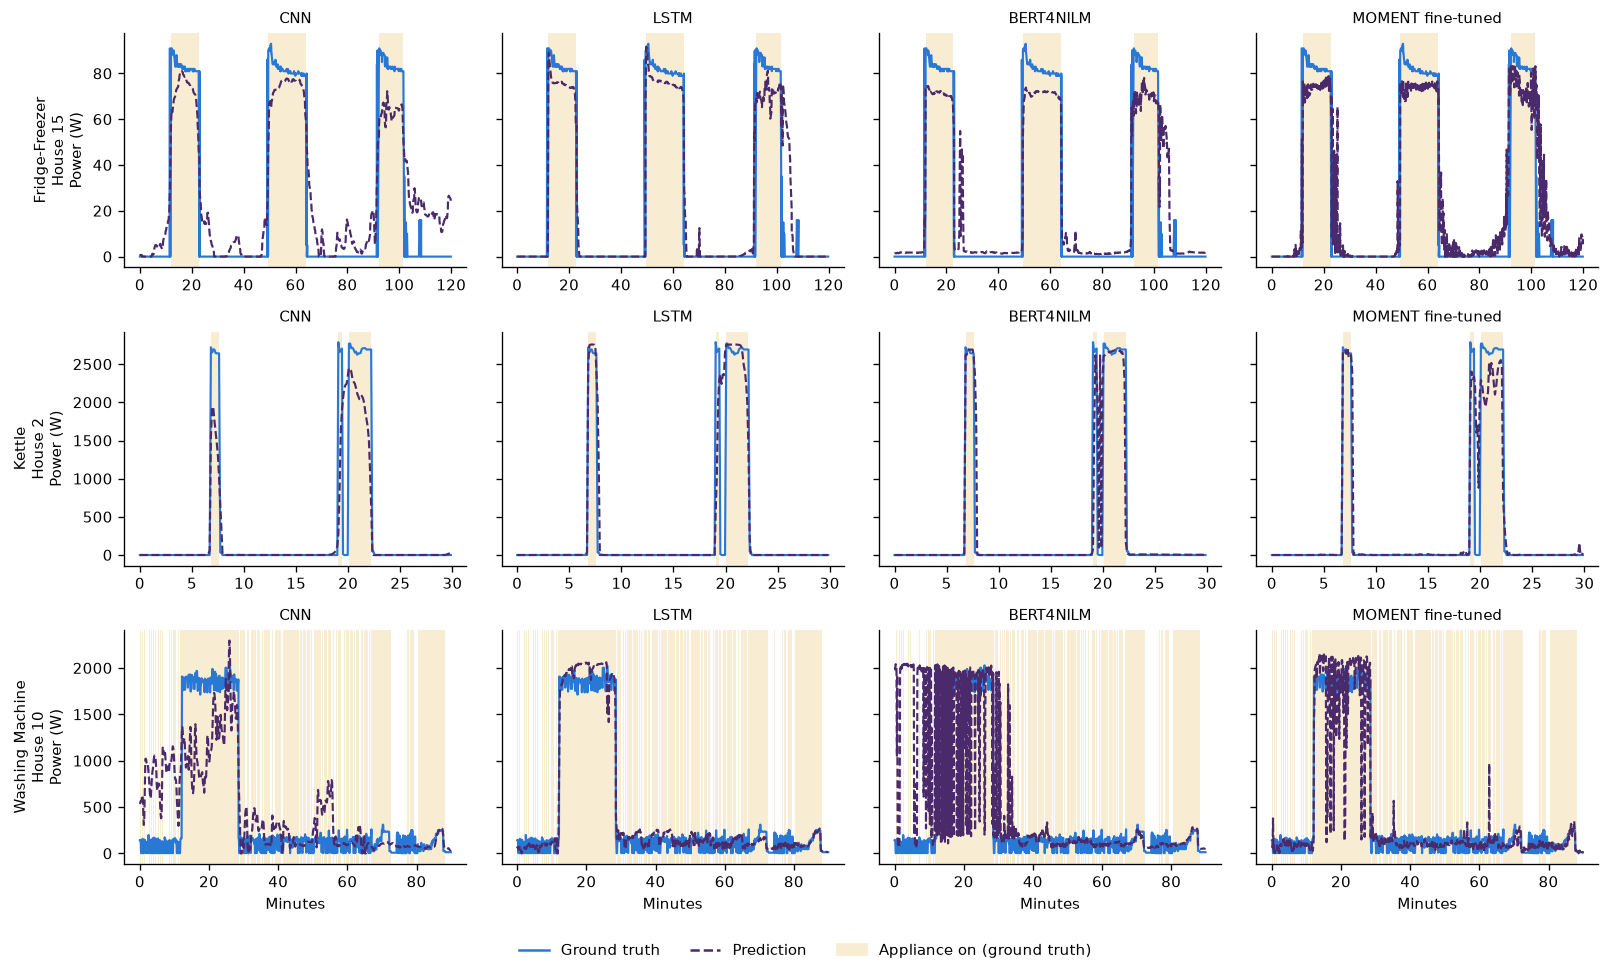

In [5]:
plot_grid(["cnn", "lstm", "bert4nilm", "moment_finetune"], "pred_vs_actual_models.png")

## MOMENT ablations

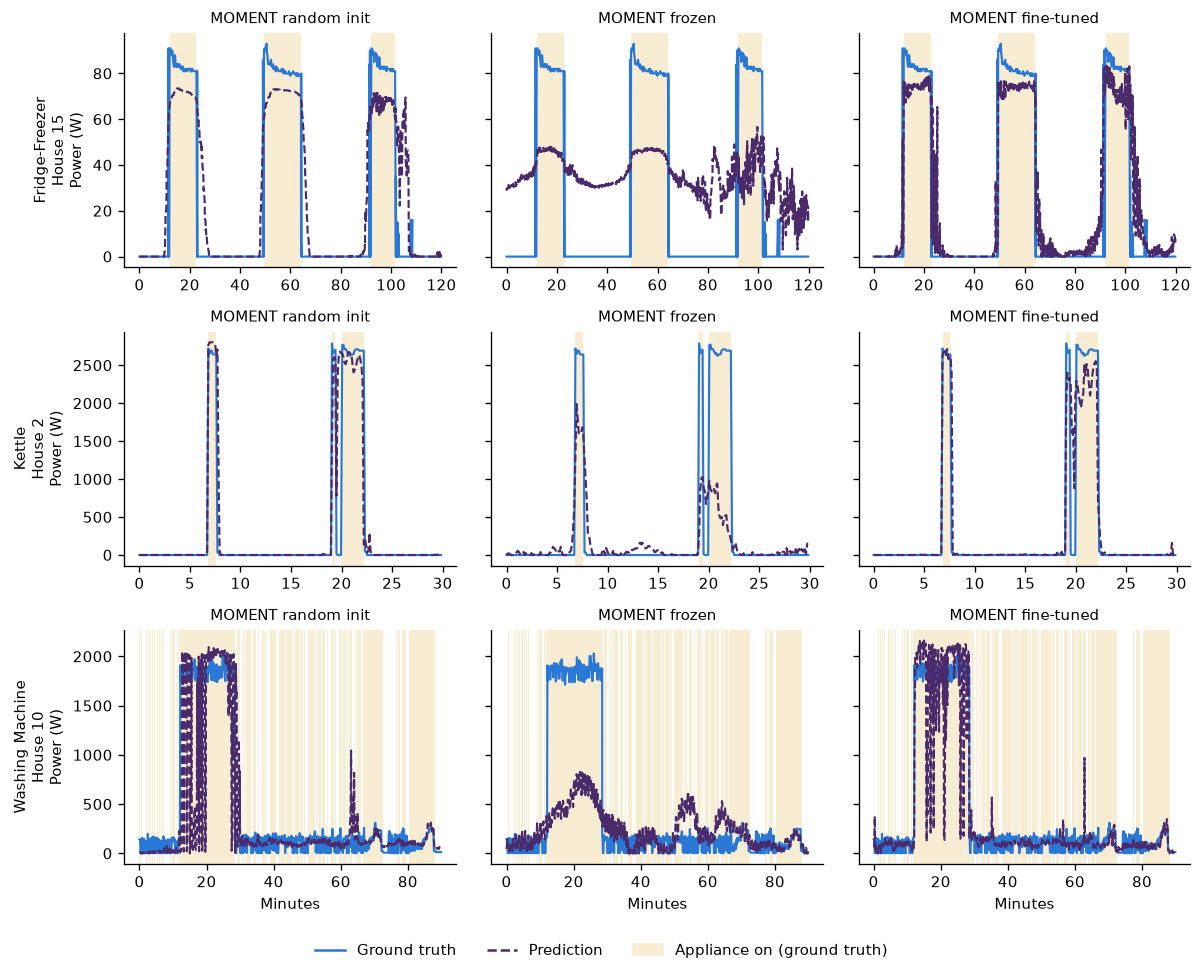

In [6]:
plot_grid(["moment_random", "moment_frozen", "moment_finetune"], "pred_vs_actual_moment.png")